# Blinkit / Zepto – Cart Abandonment & Dark-Store Replenishment Triggers
**AI Foundations for Managers · Semester 1, 2026 · Group project notebook**

**Business problem.** Quick-commerce apps such as Blinkit and Zepto promise delivery in about 10 minutes from small *dark stores*. Two problems hurt revenue:
1. **Cart abandonment** – customers add items but leave without paying (high delivery fee, long ETA, items out of stock).
2. **Stock-outs at the dark store** – when an item runs out, carts lose items and customers abandon. Lost sales never appear in sales data.

**Stakeholders:** dark-store manager, supply-chain / replenishment planner, category manager, growth & marketing team, finance, customers.

**Decisions this project improves**
| Decision | Current process (assumed) | AI-supported process |
|---|---|---|
| Which carts need a recovery action? | Same reminder / coupon for everyone, or nothing | Score each cart's abandonment risk and act only on high-risk carts |
| When and how much to restock each product? | Fixed weekly order by the store manager | Daily demand forecast + reorder-point **trigger** + suggested order quantity |

> **Data note:** all data in this notebook is **synthetic (dummy)**, generated below, as allowed by the project brief. It does not represent real Blinkit or Zepto data.

## Step 1 – Generate synthetic data

In [1]:
# STEP 1A: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make results reproducible
np.random.seed(42)

print("QuickCommerce AI Project")
print("Libraries imported successfully!")

QuickCommerce AI Project
Libraries imported successfully!


In [2]:
# STEP 1B: Generate synthetic cart data

n = 5000

cart_value = np.random.uniform(100, 2000, n).round(2)
delivery_fee = np.random.choice([0, 10, 20, 30, 40, 50], n)
items_in_cart = np.random.randint(1, 16, n)
out_of_stock_items = np.random.choice([0, 1, 2], n, p=[0.85, 0.12, 0.03])
eta_minutes = np.random.randint(5, 46, n)
previous_orders = np.random.randint(0, 31, n)
discount_percent = np.random.choice([0, 5, 10, 15, 20], n)

# Simulate a relationship between cart characteristics
# and the likelihood of abandonment.
# These assumptions are for demonstration, not real company data.

risk_score = (
    -1.2
    + 0.035 * delivery_fee
    + 0.035 * (eta_minutes - 20)
    + 0.75 * out_of_stock_items
    - 0.035 * previous_orders
    - 0.025 * discount_percent
    + 0.15 * (items_in_cart <= 2)
)

# Convert risk score into a probability between 0 and 1
abandonment_probability = 1 / (1 + np.exp(-risk_score))

# Generate the observed outcome for each simulated session
abandoned = np.random.binomial(1, abandonment_probability)

cart_data = pd.DataFrame({
    "session_id": [f"S{i:05d}" for i in range(1, n + 1)],
    "cart_value": cart_value,
    "delivery_fee": delivery_fee,
    "items_in_cart": items_in_cart,
    "out_of_stock_items": out_of_stock_items,
    "eta_minutes": eta_minutes.astype(float),
    "previous_orders": previous_orders,
    "discount_percent": discount_percent,
    "abandoned": abandoned
})

print("Cart dataset created successfully!")
print("Dataset shape:", cart_data.shape)
display(cart_data.head(10))

Cart dataset created successfully!
Dataset shape: (5000, 9)


,session_id,cart_value,delivery_fee,items_in_cart,out_of_stock_items,eta_minutes,previous_orders,discount_percent,abandoned
0,S00001,811.63,20,15,0,40.0,22,10,0
1,S00002,1906.36,20,11,1,7.0,23,15,0
2,S00003,1490.79,50,4,0,8.0,9,20,0
3,S00004,1237.45,30,7,0,35.0,17,15,0
4,S00005,396.44,20,9,0,6.0,22,5,0
5,S00006,396.39,40,14,0,18.0,15,15,1
6,S00007,210.36,20,8,0,41.0,28,20,0
7,S00008,1745.73,40,8,1,35.0,11,15,1
8,S00009,1242.12,20,9,0,6.0,18,0,0
9,S00010,1445.34,40,14,2,35.0,23,20,1


In [3]:
# STEP 1C: Add realistic data-quality problems (so we can clean them in Step 2)
# Real app logs are never perfect. We deliberately add three common problems.

# 1. Duplicate events: the app sometimes logs the same session twice (1%)
duplicates = cart_data.sample(frac=0.01, random_state=1)

# 2. Missing ETA: the delivery-time service timed out for 2% of sessions
missing_idx = cart_data.sample(frac=0.02, random_state=2).index
cart_data.loc[missing_idx, "eta_minutes"] = np.nan

# 3. Invalid cart values: a pricing bug recorded 0 or negative values (0.5%)
bad_idx = cart_data.sample(frac=0.005, random_state=3).index
cart_data.loc[bad_idx, "cart_value"] = np.random.choice([0, -1], len(bad_idx))

cart_data_raw = pd.concat([cart_data, duplicates]).sample(frac=1, random_state=4).reset_index(drop=True)
cart_data_raw.to_csv("cart_data_raw.csv", index=False)

print("Raw cart data saved as cart_data_raw.csv")
print("Rows (including duplicates):", len(cart_data_raw))

Raw cart data saved as cart_data_raw.csv
Rows (including duplicates): 5050


In [4]:
# STEP 1D: Generate synthetic dark-store inventory and sales history
# One dark store, 30 products, 90 days. Each product is restocked from the
# mother warehouse; the lead time (days) is fixed per product.

inventory_records = []

products = [
    "Milk", "Bread", "Eggs", "Rice", "Wheat Flour",
    "Cooking Oil", "Sugar", "Tea", "Coffee", "Butter",
    "Cheese", "Yogurt", "Bananas", "Apples", "Potatoes",
    "Onions", "Tomatoes", "Biscuits", "Chips", "Chocolate",
    "Soft Drinks", "Bottled Water", "Instant Noodles",
    "Pasta", "Detergent", "Shampoo", "Soap", "Toothpaste",
    "Baby Wipes", "Ice Cream"
]

product_info = {}

for product in products:

    # Product characteristics stay the same every day
    average_demand = np.random.randint(15, 120)
    demand_variation = max(3, 0.15 * average_demand)   # daily ups and downs
    lead_time = int(np.random.choice([1, 2, 3]))         # days to restock
    unit_cost = round(np.random.uniform(10, 200), 2)     # purchase cost (₹)
    selling_price = round(unit_cost * 1.25, 2)           # 25% gross margin

    product_info[product] = (average_demand, demand_variation, lead_time,
                             unit_cost, selling_price)

    # Simulate 90 days of sales history
    for day in range(90):

        weekday = day % 7
        weekend_factor = 1.20 if weekday in [5, 6] else 1.0

        daily_demand = max(
            0,
            int(np.random.normal(average_demand * weekend_factor, demand_variation))
        )

        inventory_records.append({
            "day": day + 1,
            "product": product,
            "daily_sales": daily_demand,
            "supplier_lead_time": lead_time,
            "unit_cost": unit_cost,
            "selling_price": selling_price
        })

inventory_data = pd.DataFrame(inventory_records)

# Safety stock with the standard formula:  z x sigma x sqrt(lead time)
# z = 1.65 gives roughly a 95% service level
Z = 1.65
sales_std = inventory_data.groupby("product")["daily_sales"].std()
lead_times = inventory_data.groupby("product")["supplier_lead_time"].first()
safety_stock = np.ceil(Z * sales_std * np.sqrt(lead_times)).astype(int)
inventory_data["safety_stock"] = inventory_data["product"].map(safety_stock)

# Current stock snapshot: between 0.6x and 2.2x of the demand expected
# during the lead time, so some products need a reorder and others don't
current_stock = {}
for product in products:
    avg_sales = inventory_data.loc[inventory_data["product"] == product, "daily_sales"].mean()
    lead_time = product_info[product][2]
    current_stock[product] = int(np.random.uniform(0.6, 2.2) * avg_sales * lead_time)

inventory_data["current_stock"] = inventory_data["product"].map(current_stock)

inventory_data.to_csv("inventory_data.csv", index=False)

print("Inventory dataset created successfully!")
print("Dataset shape:", inventory_data.shape)
display(inventory_data.head(10))

Inventory dataset created successfully!
Dataset shape: (2700, 8)


,day,product,daily_sales,supplier_lead_time,unit_cost,selling_price,safety_stock,current_stock
0,1,Milk,102,1,197.15,246.44,28,77
1,2,Milk,76,1,197.15,246.44,28,77
2,3,Milk,87,1,197.15,246.44,28,77
3,4,Milk,86,1,197.15,246.44,28,77
4,5,Milk,80,1,197.15,246.44,28,77
5,6,Milk,129,1,197.15,246.44,28,77
6,7,Milk,86,1,197.15,246.44,28,77
7,8,Milk,61,1,197.15,246.44,28,77
8,9,Milk,86,1,197.15,246.44,28,77
9,10,Milk,77,1,197.15,246.44,28,77


## Step 2 – Data quality checks and cleaning

In [5]:
# STEP 2A: Data-quality report on the raw cart data

cart_raw = pd.read_csv("cart_data_raw.csv")

quality_report = pd.DataFrame({
    "Check": [
        "Total rows",
        "Duplicate sessions",
        "Missing eta_minutes",
        "Cart value <= 0 (invalid)",
        "Missing values in other columns"
    ],
    "Result": [
        len(cart_raw),
        cart_raw.duplicated("session_id").sum(),
        cart_raw["eta_minutes"].isnull().sum(),
        (cart_raw["cart_value"] <= 0).sum(),
        cart_raw.drop(columns="eta_minutes").isnull().sum().sum()
    ]
})

display(quality_report)

,Check,Result
0,Total rows,5050
1,Duplicate sessions,50
2,Missing eta_minutes,100
3,Cart value <= 0 (invalid),25
4,Missing values in other columns,0


In [6]:
# STEP 2B: Clean the cart data

cart_data = cart_raw.copy()

# 1. Remove duplicate events - keep the first record of each session
cart_data = cart_data.drop_duplicates("session_id")

# 2. Remove rows with impossible cart values
cart_data = cart_data[cart_data["cart_value"] > 0]

# 3. Fill missing ETA with the median ETA (robust to outliers)
median_eta = cart_data["eta_minutes"].median()
cart_data["eta_minutes"] = cart_data["eta_minutes"].fillna(median_eta)

cart_data = cart_data.sort_values("session_id").reset_index(drop=True)
cart_data.to_csv("cart_data.csv", index=False)

print("Rows before cleaning:", len(cart_raw))
print("Rows after cleaning: ", len(cart_data))
print("Missing values left: ", cart_data.isnull().sum().sum())
print("Median ETA used for filling:", median_eta, "minutes")
print("\nClean data saved as cart_data.csv (used by the models and the app)")

Rows before cleaning: 5050
Rows after cleaning:  4975
Missing values left:  0
Median ETA used for filling: 25.0 minutes

Clean data saved as cart_data.csv (used by the models and the app)


In [7]:
# STEP 2C: Check the inventory data

inventory_data = pd.read_csv("inventory_data.csv")

print("INVENTORY DATA")
print("Rows and columns:", inventory_data.shape)
print("Missing values:", inventory_data.isnull().sum().sum())
print("Duplicate rows:", inventory_data.duplicated().sum())
print("Number of products:", inventory_data["product"].nunique())
print("Days of history:", inventory_data["day"].nunique())

# Each product must have a single lead time and price
print("Products with more than one lead time:",
      (inventory_data.groupby("product")["supplier_lead_time"].nunique() > 1).sum())

INVENTORY DATA
Rows and columns: (2700, 8)
Missing values: 0
Duplicate rows: 0
Number of products: 30
Days of history: 90
Products with more than one lead time: 0


## Step 3 – Exploratory analysis

Completed carts (0): 3314
Abandoned carts (1): 1661
Overall abandonment rate: 33.39%


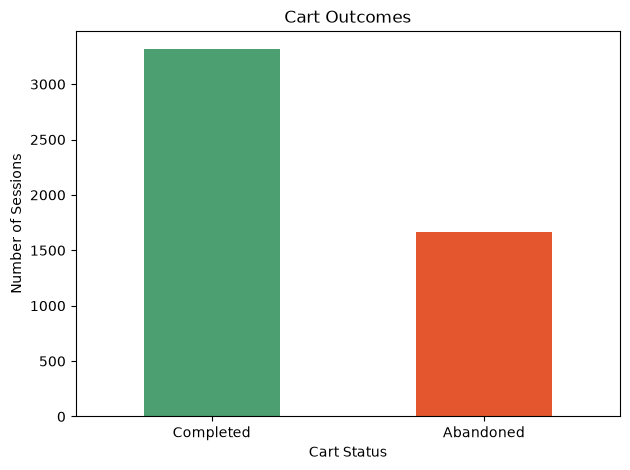

In [8]:
# STEP 3A: Overall abandonment

cart_counts = cart_data["abandoned"].value_counts().sort_index()

print("Completed carts (0):", cart_counts.get(0, 0))
print("Abandoned carts (1):", cart_counts.get(1, 0))

abandonment_rate = cart_data["abandoned"].mean() * 100
print(f"Overall abandonment rate: {abandonment_rate:.2f}%")

cart_data["abandoned"].map({0: "Completed", 1: "Abandoned"}).value_counts().reindex(
    ["Completed", "Abandoned"]).plot(kind="bar", color=["#4C9F70", "#E4572E"])
plt.title("Cart Outcomes")
plt.xlabel("Cart Status")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

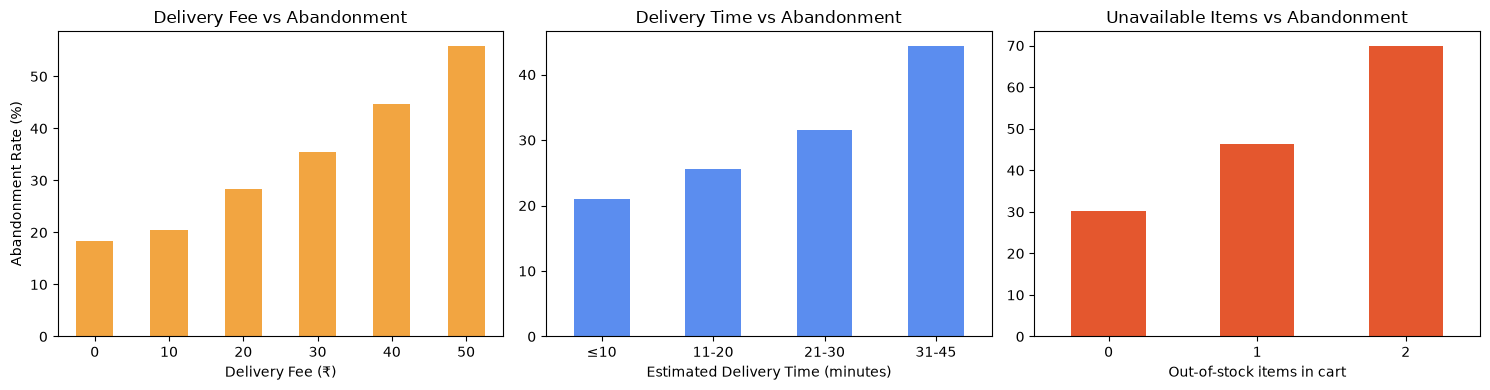

In [9]:
# STEP 3B: Abandonment rate by delivery fee, ETA and unavailable items

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

(cart_data.groupby("delivery_fee")["abandoned"].mean() * 100).plot(
    kind="bar", ax=axes[0], color="#F2A541")
axes[0].set_title("Delivery Fee vs Abandonment")
axes[0].set_xlabel("Delivery Fee (₹)")
axes[0].set_ylabel("Abandonment Rate (%)")
axes[0].tick_params(axis="x", rotation=0)

eta_band = pd.cut(cart_data["eta_minutes"], [0, 10, 20, 30, 46],
                  labels=["≤10", "11-20", "21-30", "31-45"])
(cart_data.groupby(eta_band, observed=True)["abandoned"].mean() * 100).plot(
    kind="bar", ax=axes[1], color="#5B8DEF")
axes[1].set_title("Delivery Time vs Abandonment")
axes[1].set_xlabel("Estimated Delivery Time (minutes)")
axes[1].tick_params(axis="x", rotation=0)

(cart_data.groupby("out_of_stock_items")["abandoned"].mean() * 100).plot(
    kind="bar", ax=axes[2], color="#E4572E")
axes[2].set_title("Unavailable Items vs Abandonment")
axes[2].set_xlabel("Out-of-stock items in cart")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [10]:
# STEP 3C: Business impact – how much revenue do stock-outs cost us?
# Link between the two halves of the project: unavailable items -> abandonment.

rate_no_oos = cart_data.loc[cart_data["out_of_stock_items"] == 0, "abandoned"].mean()
oos_carts = cart_data[cart_data["out_of_stock_items"] > 0]
rate_oos = oos_carts["abandoned"].mean()

# Extra carts lost only because something was out of stock
extra_abandoned = (rate_oos - rate_no_oos) * len(oos_carts)
revenue_lost_to_stockouts = extra_abandoned * oos_carts["cart_value"].mean()

total_abandoned_value = cart_data.loc[cart_data["abandoned"] == 1, "cart_value"].sum()

stockout_impact = pd.Series({
    "Carts with at least one out-of-stock item": len(oos_carts),
    "Share of all carts (%)": len(oos_carts) / len(cart_data) * 100,
    "Abandonment rate – no stock-out (%)": rate_no_oos * 100,
    "Abandonment rate – with stock-out (%)": rate_oos * 100,
    "Extra carts abandoned because of stock-outs": extra_abandoned,
    "Revenue lost to stock-out abandonment (₹)": revenue_lost_to_stockouts,
    "Total value of all abandoned carts (₹)": total_abandoned_value,
})
display(stockout_impact.round(1).to_frame("Value"))

print(f"Stock-outs explain about {revenue_lost_to_stockouts / total_abandoned_value:.0%} "
      "of abandoned cart value, even though only "
      f"{len(oos_carts) / len(cart_data):.0%} of carts have an unavailable item.")
print("-> Better replenishment (Steps 6-7) directly reduces cart abandonment.")

,Value
Carts with at least one out-of-stock item,755.0
Share of all carts (%),15.2
Abandonment rate – no stock-out (%),30.3
Abandonment rate – with stock-out (%),50.7
Extra carts abandoned because of stock-outs,154.4
Revenue lost to stock-out abandonment (₹),164541.2
Total value of all abandoned carts (₹),1733348.2


Stock-outs explain about 9% of abandoned cart value, even though only 15% of carts have an unavailable item.
-> Better replenishment (Steps 6-7) directly reduces cart abandonment.


In [11]:
# STEP 3D: Product summary and current stock position

product_summary = (
    inventory_data.groupby("product")
    .agg(
        average_daily_sales=("daily_sales", "mean"),
        sales_std=("daily_sales", "std"),
        current_stock=("current_stock", "first"),
        supplier_lead_time=("supplier_lead_time", "first"),
        safety_stock=("safety_stock", "first"),
        selling_price=("selling_price", "first")
    )
    .round(2)
)

product_summary["days_of_cover"] = (
    product_summary["current_stock"] / product_summary["average_daily_sales"]
).round(1)

display(product_summary.sort_values("days_of_cover").head(10))

,average_daily_sales,sales_std,current_stock,supplier_lead_time,safety_stock,selling_price,days_of_cover
product,,,,,,,
Biscuits,15.93,3.30,11,1,6,45.82,0.7
Milk,89.28,16.43,77,1,28,246.44,0.9
Eggs,89.88,14.12,107,1,24,73.12,1.2
Instant Noodles,15.48,3.45,19,1,6,194.12,1.2
Pasta,18.24,3.16,24,1,6,192.86,1.3
Tomatoes,84.33,15.79,133,1,27,186.54,1.6
Baby Wipes,124.83,21.31,216,2,50,23.29,1.7
Ice Cream,123.08,19.30,224,1,32,185.84,1.8
Wheat Flour,82.89,13.75,151,2,33,146.85,1.8


stock_status
Stock Sufficient    18
Reorder Required    12
Name: count, dtype: int64


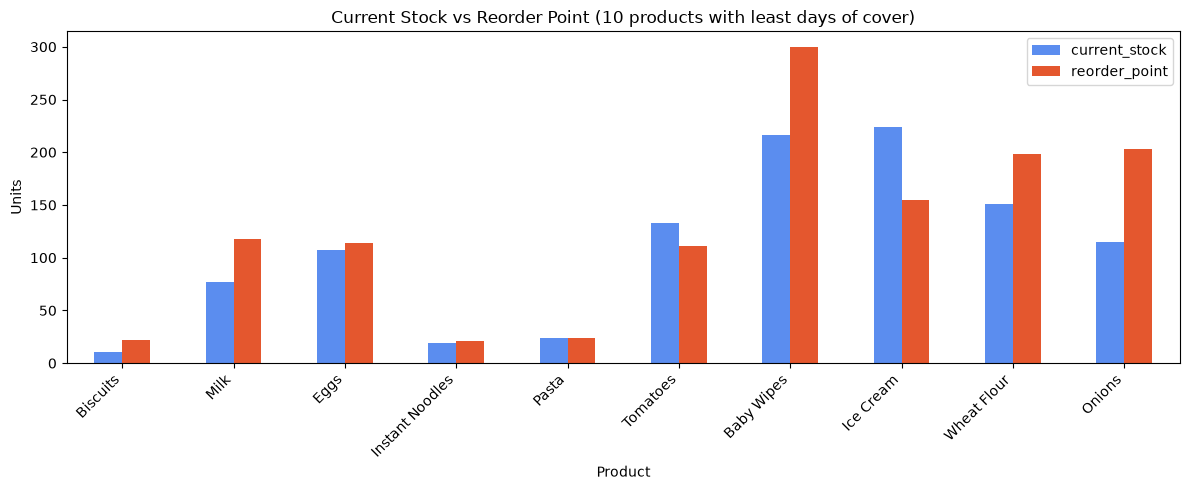

In [12]:
# STEP 3E: Rule-based reorder check (before using AI forecasts)

product_summary["reorder_point"] = (
    product_summary["average_daily_sales"] * product_summary["supplier_lead_time"]
    + product_summary["safety_stock"]
)

product_summary["stock_status"] = np.where(
    product_summary["current_stock"] <= product_summary["reorder_point"],
    "Reorder Required", "Stock Sufficient"
)

print(product_summary["stock_status"].value_counts())

lowest = product_summary.sort_values("days_of_cover").head(10)
lowest[["current_stock", "reorder_point"]].plot(kind="bar", figsize=(12, 5),
                                               color=["#5B8DEF", "#E4572E"])
plt.title("Current Stock vs Reorder Point (10 products with least days of cover)")
plt.xlabel("Product")
plt.ylabel("Units")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Step 4 – AI Model 1: Predict cart abandonment
**AI type:** supervised machine learning – binary classification (abandoned = 1 / completed = 0).
**Alternatives considered:** a simple rule ("send a coupon to every cart with a delivery fee") – cheap but untargeted; we use it as the business baseline.

In [13]:
# STEP 4A: Import machine-learning libraries

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
import joblib

print("Machine-learning libraries imported successfully!")

Machine-learning libraries imported successfully!


In [14]:
# STEP 4B: Prepare features and split the data

features = [
    "cart_value", "delivery_fee", "items_in_cart", "out_of_stock_items",
    "eta_minutes", "previous_orders", "discount_percent"
]

X = cart_data[features]
y = cart_data["abandoned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training sessions:", len(X_train))
print("Testing sessions:", len(X_test))
print(f"Abandonment rate in training data: {y_train.mean():.1%}")

Training sessions: 3980
Testing sessions: 995
Abandonment rate in training data: 33.4%


In [15]:
# STEP 4C: Train three models

# Model 1: Logistic Regression (simple, explainable)
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Model 2: Logistic Regression with balanced class weights.
# Abandoned carts are the minority (~1 in 3), so a plain model under-predicts them.
# class_weight="balanced" gives more importance to abandoned carts while training.
balanced_logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# Model 3: Random Forest (non-linear, many decision trees)
random_forest_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_leaf=5,
    random_state=42, class_weight="balanced"
)

cart_models = {
    "Logistic Regression": logistic_model,
    "Logistic Regression (balanced)": balanced_logistic_model,
    "Random Forest": random_forest_model,
}

for name, model in cart_models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Logistic Regression (balanced) trained successfully!


Random Forest trained successfully!


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Explainable?
0,Logistic Regression,0.727,0.649,0.395,0.491,0.741,Yes – coefficients
1,Logistic Regression (balanced),0.671,0.506,0.663,0.574,0.741,Yes – coefficients
2,Random Forest,0.691,0.534,0.596,0.563,0.732,Partly – feature importance


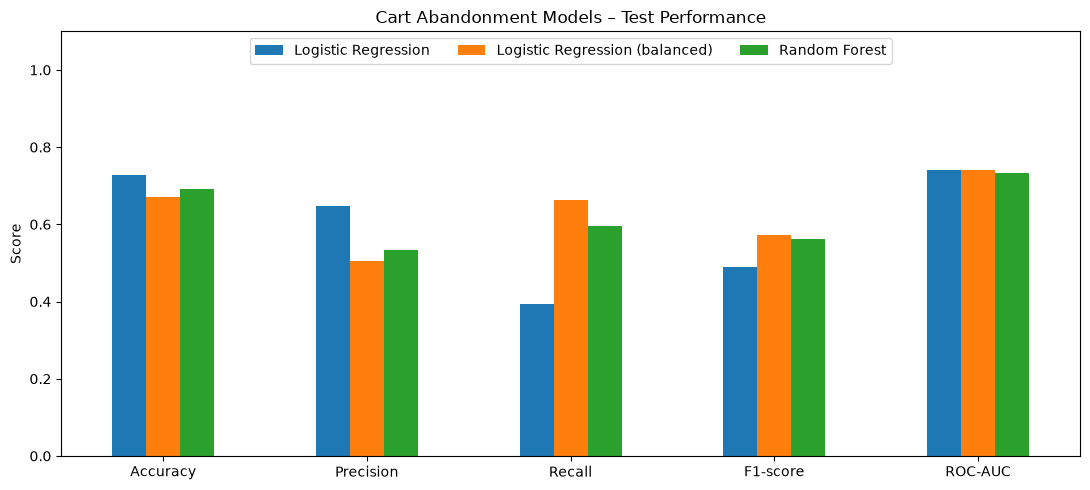

In [16]:
# STEP 4D: Compare the models on the test data

def evaluate_model(name, model):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Explainable?": "Yes – coefficients" if "Logistic" in name else "Partly – feature importance",
    }

comparison = pd.DataFrame([evaluate_model(n, m) for n, m in cart_models.items()])
display(comparison.round(3))

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
comparison.set_index("Model")[metrics].T.plot(kind="bar", figsize=(11, 5))
plt.title("Cart Abandonment Models – Test Performance")
plt.ylabel("Score")

plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

### How we choose the best model
The business goal is to **catch carts that are about to be abandoned** so we can act. Missing an abandoner costs a whole cart; a wrongly flagged cart only costs a small nudge. So our criteria, in order:
1. **Ranking quality (ROC-AUC)** – the model must separate risky from safe carts. Models within 0.01 AUC of the best are treated as equal.
2. **Recall** – among those, pick the one that catches the most abandoners.
3. **Explainability** – managers must understand *why* a cart is flagged; on a tie, prefer the simpler model.

In [17]:
# STEP 4E: Apply the selection criteria

best_auc = comparison["ROC-AUC"].max()
shortlist = comparison[comparison["ROC-AUC"] >= best_auc - 0.01]
best_row = shortlist.sort_values(["Recall", "ROC-AUC"], ascending=False).iloc[0]

best_model_name = best_row["Model"]
best_cart_model = cart_models[best_model_name]

print("Models within 0.01 ROC-AUC of the best:", list(shortlist["Model"]))
print(f"\nSelected model: {best_model_name}")
print(f"  ROC-AUC {best_row['ROC-AUC']:.3f} | Recall {best_row['Recall']:.3f} | F1 {best_row['F1-score']:.3f}")

plain_recall = comparison.loc[comparison["Model"] == "Logistic Regression", "Recall"].iloc[0]
print(f"\nThe plain Logistic Regression caught only {plain_recall:.0%} of abandoners; "
      f"the selected model catches {best_row['Recall']:.0%}.")

Models within 0.01 ROC-AUC of the best: ['Logistic Regression', 'Logistic Regression (balanced)', 'Random Forest']

Selected model: Logistic Regression (balanced)
  ROC-AUC 0.741 | Recall 0.663 | F1 0.574

The plain Logistic Regression caught only 39% of abandoners; the selected model catches 66%.


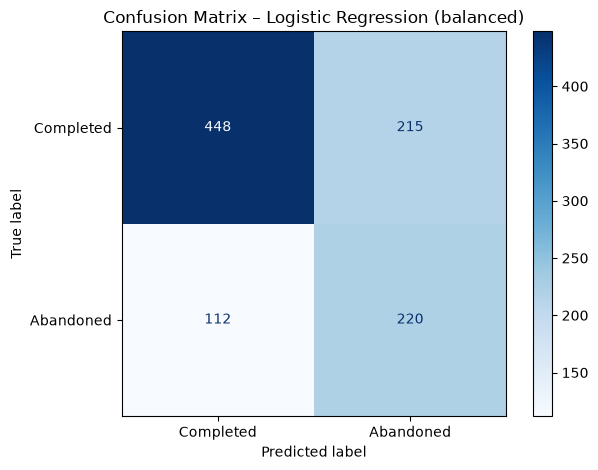

              precision    recall  f1-score   support

   Completed       0.80      0.68      0.73       663
   Abandoned       0.51      0.66      0.57       332

    accuracy                           0.67       995
   macro avg       0.65      0.67      0.65       995
weighted avg       0.70      0.67      0.68       995



In [18]:
# STEP 4F: Confusion matrix and detailed report for the selected model

best_predictions = best_cart_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Completed", "Abandoned"], cmap="Blues"
)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, best_predictions,
                            target_names=["Completed", "Abandoned"], zero_division=0))

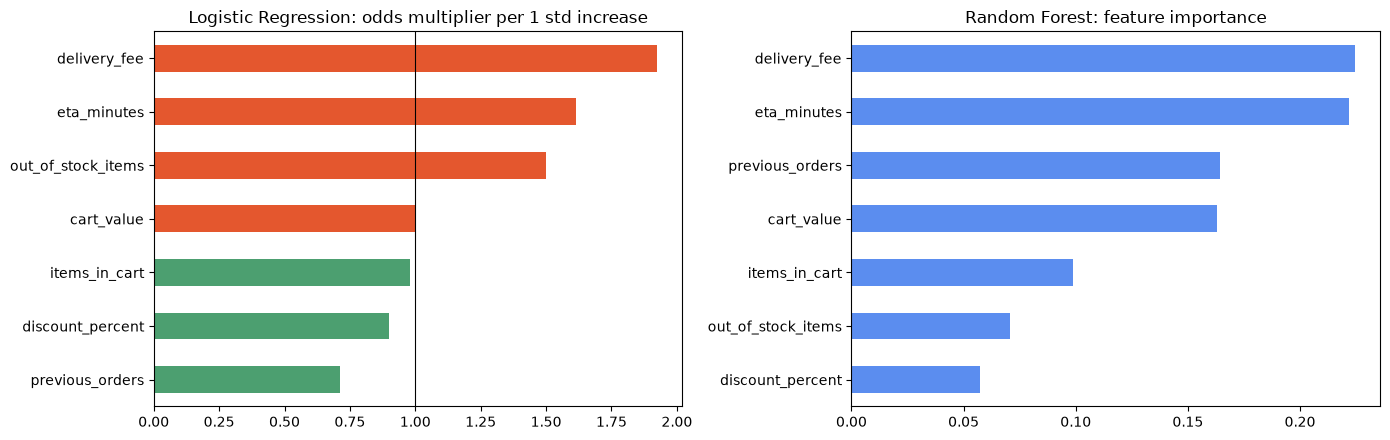

,LR odds multiplier,RF importance
previous_orders,0.71,0.164
discount_percent,0.90,0.057
items_in_cart,0.98,0.099
cart_value,1.00,0.163
out_of_stock_items,1.50,0.071
eta_minutes,1.61,0.222
delivery_fee,1.92,0.224


In [19]:
# STEP 4G: What drives abandonment? (explainability)

# Logistic Regression: how much the odds of abandonment change when a
# feature goes up by one standard deviation (>1 raises risk, <1 lowers risk)
coefficients = balanced_logistic_model.named_steps["classifier"].coef_[0]
odds_change = pd.Series(np.exp(coefficients), index=features).sort_values()

# Random Forest: feature importance
rf_importance = pd.Series(random_forest_model.feature_importances_, index=features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
odds_change.plot(kind="barh", ax=axes[0],
                 color=["#E4572E" if v > 1 else "#4C9F70" for v in odds_change])
axes[0].axvline(1, color="black", linewidth=0.8)
axes[0].set_title("Logistic Regression: odds multiplier per 1 std increase")
rf_importance.plot(kind="barh", ax=axes[1], color="#5B8DEF")
axes[1].set_title("Random Forest: feature importance")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"LR odds multiplier": odds_change.round(2),
                      "RF importance": rf_importance.round(3)}).sort_values("LR odds multiplier"))

**Why does *out_of_stock_items* look weak in the Random Forest chart?**
Random Forest importance measures how often and how usefully a feature is used to split carts *across the whole dataset*. Only about 15 % of carts contain an unavailable item, so the feature is used rarely, even though its effect is large when it occurs: abandonment rises from about 30 % (no stock-out) to about 46 % (1 item) and about 70 % (2 items) – see Step 3B. Logistic Regression measures the effect *per unit*, so it shows out-of-stock as a strong driver. **Rare but powerful** features are under-ranked by tree importance; this is why we look at both views.

In [20]:
# STEP 4H: Turn risk scores into a business decision
# Assumption (illustrative): a recovery nudge (fee waiver / coupon) costs ₹20,
# saves 25% of the carts that would otherwise be abandoned, and the
# contribution margin on a saved cart is 20% of its value.

NUDGE_COST, SAVE_RATE, MARGIN = 20, 0.25, 0.20

test_probabilities = best_cart_model.predict_proba(X_test)[:, 1]
test_values = X_test["cart_value"].to_numpy()
actual = y_test.to_numpy()

rows = []
for threshold in np.arange(0.1, 0.91, 0.1):
    nudged = test_probabilities >= threshold
    saved_carts = (nudged & (actual == 1)).sum() * SAVE_RATE
    saved_revenue = (test_values * (nudged & (actual == 1))).sum() * SAVE_RATE
    cost = nudged.sum() * NUDGE_COST
    rows.append({"Risk threshold": round(threshold, 1), "Carts nudged": nudged.sum(),
                 "Carts saved": saved_carts, "Revenue saved (₹)": saved_revenue,
                 "Nudge cost (₹)": cost, "Net profit (₹)": saved_revenue * MARGIN - cost})

# Baseline business rule: nudge every cart (no AI)
all_saved = (test_values * actual).sum() * SAVE_RATE
rows.append({"Risk threshold": "No AI – nudge everyone", "Carts nudged": len(actual),
             "Carts saved": actual.sum() * SAVE_RATE, "Revenue saved (₹)": all_saved,
             "Nudge cost (₹)": len(actual) * NUDGE_COST,
             "Net profit (₹)": all_saved * MARGIN - len(actual) * NUDGE_COST})

nudge_table = pd.DataFrame(rows)
display(nudge_table.round(0))

ai_rows = nudge_table[nudge_table["Risk threshold"] != "No AI – nudge everyone"]
best_threshold = ai_rows.loc[ai_rows["Net profit (₹)"].idxmax()]
print(f"Best threshold: nudge carts with risk ≥ {best_threshold['Risk threshold']}"
      f" -> net profit ₹{best_threshold['Net profit (₹)']:,.0f} on {len(actual):,} test carts"
      f" vs ₹{nudge_table.iloc[-1]['Net profit (₹)']:,.0f} when nudging everyone.")

,Risk threshold,Carts nudged,Carts saved,Revenue saved (₹),Nudge cost (₹),Net profit (₹)
0,0.1,988,83.0,88496.0,19760,-2061.0
1,0.2,894,81.0,86710.0,17880,-538.0
2,0.3,747,75.0,78248.0,14940,710.0
3,0.4,579,67.0,70835.0,11580,2587.0
4,0.5,435,55.0,58752.0,8700,3050.0
5,0.6,288,41.0,44407.0,5760,3121.0
6,0.7,167,28.0,30475.0,3340,2755.0
7,0.8,82,16.0,15729.0,1640,1506.0
8,0.9,18,4.0,4352.0,360,510.0
9,No AI – nudge everyone,995,83.0,88496.0,19900,-2201.0


Best threshold: nudge carts with risk ≥ 0.6 -> net profit ₹3,121 on 995 test carts vs ₹-2,201 when nudging everyone.


In [21]:
# STEP 4I: Predict abandonment risk for a new cart

new_cart = pd.DataFrame([{
    "cart_value": 450, "delivery_fee": 40, "items_in_cart": 3,
    "out_of_stock_items": 1, "eta_minutes": 35, "previous_orders": 1,
    "discount_percent": 0
}])

probability = best_cart_model.predict_proba(new_cart)[0, 1]
print(f"Estimated abandonment probability: {probability:.1%}")

if probability >= 0.70:
    print("Recommendation: High risk – offer a substitute for the unavailable item or waive the fee.")
elif probability >= 0.40:
    print("Recommendation: Medium risk – show clearer ETA or a gentle reminder.")
else:
    print("Recommendation: Low risk – continue the normal customer journey.")

Estimated abandonment probability: 91.1%
Recommendation: High risk – offer a substitute for the unavailable item or waive the fee.


In [22]:
# STEP 4J: Save the selected model

joblib.dump(best_cart_model, "cart_abandonment_model.pkl")
comparison.to_csv("cart_model_comparison.csv", index=False)
print(f"Saved {best_model_name} as cart_abandonment_model.pkl")

Saved Logistic Regression (balanced) as cart_abandonment_model.pkl


## Step 5 – AI Model 2: Forecast daily demand per product
**AI type:** supervised machine learning – regression on time-series features (previous days' sales).
**Baseline:** 7-day moving average – what a store manager would typically use.

In [23]:
# STEP 5A: Create time-based features

forecast_data = inventory_data.sort_values(["product", "day"]).copy()

for lag in [1, 2, 3]:
    forecast_data[f"sales_lag_{lag}"] = forecast_data.groupby("product")["daily_sales"].shift(lag)

forecast_data["sales_7day_avg"] = (
    forecast_data.groupby("product")["daily_sales"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

# Day of the week: day 1 is Monday in our simulated dataset
forecast_data["weekday"] = (forecast_data["day"] - 1) % 7

forecast_data["target_demand"] = forecast_data["daily_sales"]
forecast_data = forecast_data.dropna().reset_index(drop=True)

print("Rows available:", len(forecast_data))
display(forecast_data.head())

Rows available: 2490


,day,product,daily_sales,supplier_lead_time,unit_cost,selling_price,safety_stock,current_stock,sales_lag_1,sales_lag_2,sales_lag_3,sales_7day_avg,weekday,target_demand
0,8,Apples,76,2,106.71,133.39,30,281,65.0,81.0,65.0,65.285714,0,76
1,9,Apples,68,2,106.71,133.39,30,281,76.0,65.0,81.0,66.142857,1,68
2,10,Apples,57,2,106.71,133.39,30,281,68.0,76.0,65.0,66.714286,2,57
3,11,Apples,65,2,106.71,133.39,30,281,57.0,68.0,76.0,66.142857,3,65
4,12,Apples,74,2,106.71,133.39,30,281,65.0,57.0,68.0,68.142857,4,74


In [24]:
# STEP 5B: Chronological split – train on days 8-70, test on days 71-90
# (we never use future data to predict the past)

forecast_features = ["sales_lag_1", "sales_lag_2", "sales_lag_3", "sales_7day_avg", "weekday"]

train_forecast = forecast_data[forecast_data["day"] <= 70].copy()
test_forecast = forecast_data[forecast_data["day"] > 70].copy()

X_train_inv, y_train_inv = train_forecast[forecast_features], train_forecast["target_demand"]
X_test_inv, y_test_inv = test_forecast[forecast_features], test_forecast["target_demand"]

print("Training rows:", len(X_train_inv), "| Testing rows:", len(X_test_inv))

Training rows: 1890 | Testing rows: 600


In [25]:
# STEP 5C: Train the demand model and compare with the baseline

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

inventory_model = RandomForestRegressor(n_estimators=200, max_depth=10,
                                        min_samples_leaf=3, random_state=42)
inventory_model.fit(X_train_inv, y_train_inv)

test_forecast["rf_forecast"] = inventory_model.predict(X_test_inv)
test_forecast["ma_forecast"] = X_test_inv["sales_7day_avg"].to_numpy()

def forecast_scores(name, column):
    error = test_forecast[column] - test_forecast["target_demand"]
    return {"Model": name,
            "MAE (units)": error.abs().mean(),
            "RMSE (units)": np.sqrt((error ** 2).mean()),
            "MAPE (%)": (error.abs() / test_forecast["target_demand"].clip(lower=1)).mean() * 100}

forecast_comparison = pd.DataFrame([
    forecast_scores("7-day Moving Average (baseline)", "ma_forecast"),
    forecast_scores("Random Forest (AI)", "rf_forecast"),
])
display(forecast_comparison.round(2))
improvement = 1 - forecast_comparison["MAE (units)"].iloc[1] / forecast_comparison["MAE (units)"].iloc[0]
print(f"Random Forest reduces forecast error (MAE) by {improvement:.0%} versus the moving average.")

,Model,MAE (units),RMSE (units),MAPE (%)
0,7-day Moving Average (baseline),8.90,12.43,14.93
1,Random Forest (AI),8.55,11.88,14.24


Random Forest reduces forecast error (MAE) by 4% versus the moving average.


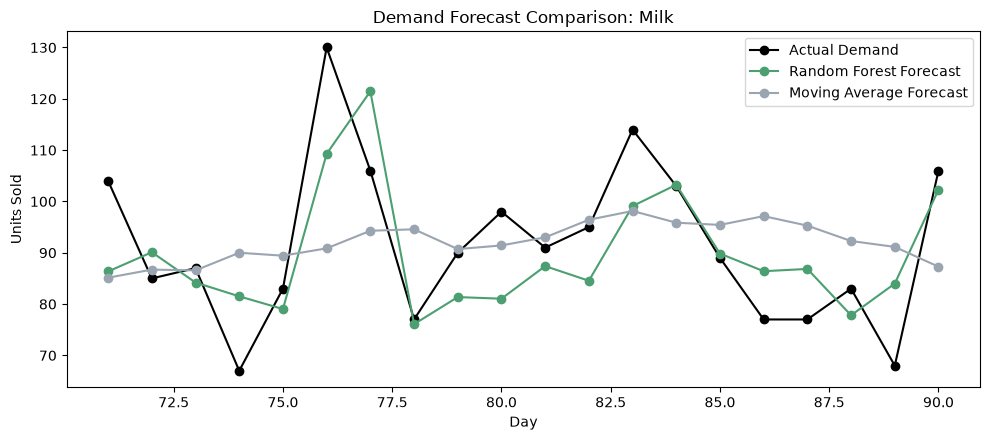

In [26]:
# STEP 5D: Plot actual vs forecast demand for one product

selected_product = "Milk"
plot_data = test_forecast[test_forecast["product"] == selected_product]

plt.figure(figsize=(10, 4.5))
plt.plot(plot_data["day"], plot_data["target_demand"], marker="o", label="Actual Demand", color="black")
plt.plot(plot_data["day"], plot_data["rf_forecast"], marker="o", label="Random Forest Forecast", color="#4C9F70")
plt.plot(plot_data["day"], plot_data["ma_forecast"], marker="o", label="Moving Average Forecast", color="#9AA5B1")
plt.title(f"Demand Forecast Comparison: {selected_product}")
plt.xlabel("Day")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# STEP 5E: Save the demand model and feature list

joblib.dump(inventory_model, "inventory_demand_model.pkl")
joblib.dump(forecast_features, "inventory_features.pkl")
forecast_comparison.to_csv("forecast_model_comparison.csv", index=False)
print("Inventory model saved successfully!")

Inventory model saved successfully!


## Step 6 – Dark-store replenishment triggers
**Trigger rule (checked every day for every product):**

Reorder point = forecast daily demand × lead time (days) + safety stock
Safety stock = 1.65 × σ(daily sales) × √lead time  (≈ 95 % service level)

If **stock on hand + stock already ordered ≤ reorder point → trigger a replenishment order** for enough units to cover the lead time plus 2 days, plus safety stock.

In [28]:
# STEP 6A: Today's trigger board (day 91)

latest_features = (
    inventory_data.sort_values(["product", "day"])
    .groupby("product").tail(7)
    .groupby("product")
    .agg(sales_lag_1=("daily_sales", lambda s: s.iloc[-1]),
         sales_lag_2=("daily_sales", lambda s: s.iloc[-2]),
         sales_lag_3=("daily_sales", lambda s: s.iloc[-3]),
         sales_7day_avg=("daily_sales", "mean"),
         last_day=("day", "max"))
    .reset_index()
)
latest_features["weekday"] = latest_features["last_day"] % 7      # weekday of the next day
latest_features["forecast_demand"] = inventory_model.predict(latest_features[forecast_features]).clip(min=0)

replenishment = (inventory_data.sort_values("day").groupby("product").tail(1)
                 .merge(latest_features[["product", "forecast_demand"]], on="product"))

REVIEW_DAYS = 2
replenishment["reorder_point"] = (replenishment["forecast_demand"] * replenishment["supplier_lead_time"]
                                  + replenishment["safety_stock"])
replenishment["days_until_stockout"] = (replenishment["current_stock"] / replenishment["forecast_demand"]).round(1)
replenishment["trigger"] = np.where(replenishment["current_stock"] <= replenishment["reorder_point"],
                                    "REORDER NOW", "OK")
replenishment["suggested_order_qty"] = np.where(
    replenishment["trigger"] == "REORDER NOW",
    np.ceil(replenishment["forecast_demand"] * (replenishment["supplier_lead_time"] + REVIEW_DAYS)
            + replenishment["safety_stock"] - replenishment["current_stock"]),
    0).astype(int)
replenishment["revenue_at_risk"] = np.where(          # sales lost if stock runs out before the order arrives
    replenishment["trigger"] == "REORDER NOW",
    np.maximum(0, replenishment["forecast_demand"] * replenishment["supplier_lead_time"]
               - replenishment["current_stock"]) * replenishment["selling_price"], 0)

trigger_board = replenishment[["product", "current_stock", "forecast_demand", "supplier_lead_time",
                               "safety_stock", "reorder_point", "days_until_stockout", "trigger",
                               "suggested_order_qty", "revenue_at_risk"]] \
    .sort_values(["trigger", "days_until_stockout"], ascending=[False, True]).round(1)

print(trigger_board["trigger"].value_counts().to_string())
display(trigger_board)
trigger_board.to_csv("trigger_board.csv", index=False)

trigger
REORDER NOW    15
OK             15


,product,current_stock,forecast_demand,supplier_lead_time,safety_stock,reorder_point,days_until_stockout,trigger,suggested_order_qty,revenue_at_risk
24,Biscuits,11,19.6,1,6,25.6,0.6,REORDER NOW,54,394.3
6,Milk,77,104.2,1,28,132.2,0.7,REORDER NOW,264,6714.6
27,Eggs,107,109.2,1,24,133.2,1.0,REORDER NOW,245,161.8
14,Pasta,24,21.1,1,6,27.1,1.1,REORDER NOW,46,0.0
21,Instant Noodles,19,16.4,1,6,22.4,1.2,REORDER NOW,37,0.0
18,Wheat Flour,151,106.1,2,33,245.1,1.4,REORDER NOW,307,8976.6
23,Onions,115,70.2,3,28,238.7,1.6,REORDER NOW,265,4759.6
4,Sugar,68,36.9,2,12,85.9,1.8,REORDER NOW,92,852.5
26,Baby Wipes,216,123.2,2,50,296.4,1.8,REORDER NOW,327,707.8
20,Butter,44,19.2,2,9,47.3,2.3,REORDER NOW,42,0.0


,Policy,Fill rate (%),Stock-out product-days,Lost revenue (₹),Average stock held (units/product)
0,Current process (weekly order),93.7,67,323245.0,180.2
1,Trigger + moving average,100.0,1,1563.4,109.3
2,AI trigger (Random Forest),100.0,2,1100.7,109.6


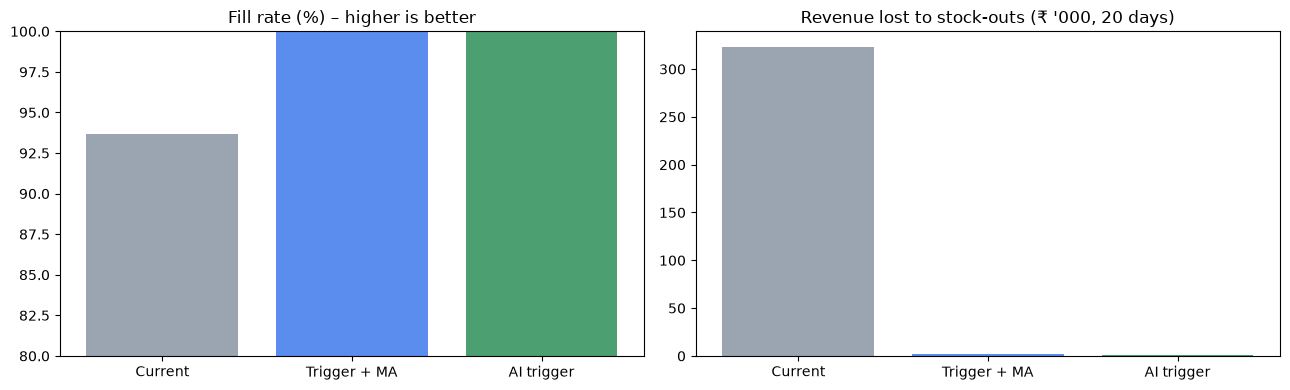

In [29]:
# STEP 6B: Back-test – would AI triggers have worked better over the last 20 days?
# We replay the real demand of days 71-90 under three policies, starting from the
# same stock, and measure fill rate, stock-out days and lost revenue.
#   1. Current process – every Monday the manager tops stock up to one week's average sales
#   2. Trigger + 7-day moving-average forecast
#   3. Trigger + Random Forest forecast (proposed AI solution)

def run_policy(policy):
    results = []
    for product, history in test_forecast.groupby("product"):
        history = history.sort_values("day")
        demand = history["target_demand"].to_numpy()
        lead = int(history["supplier_lead_time"].iloc[0])
        safety = history["safety_stock"].iloc[0]
        price = history["selling_price"].iloc[0]
        avg_sales = train_forecast.loc[train_forecast["product"] == product, "target_demand"].mean()
        forecast = history["rf_forecast" if policy == "AI trigger (Random Forest)" else "ma_forecast"].to_numpy()

        stock = avg_sales * lead + safety          # same starting stock for every policy
        arrivals = {}
        sold = lost = stockout_days = stock_held = 0
        for t, day in enumerate(history["day"]):
            stock += arrivals.pop(t, 0)            # deliveries arriving today
            sales = min(stock, demand[t])
            sold += sales
            lost += demand[t] - sales
            stockout_days += int(sales < demand[t])
            stock -= sales
            stock_held += stock
            on_order = sum(arrivals.values())
            if policy == "Current process (weekly order)":
                if (day - 1) % 7 == 0:             # every Monday: top up to one week's average sales
                    qty = max(0, round(avg_sales * 7) - stock - on_order)
                    arrivals[t + lead] = arrivals.get(t + lead, 0) + qty
            else:
                next_demand = forecast[t + 1] if t + 1 < len(forecast) else forecast[t]
                if stock + on_order <= next_demand * lead + safety:
                    qty = np.ceil(next_demand * (lead + REVIEW_DAYS) + safety - stock - on_order)
                    arrivals[t + lead] = arrivals.get(t + lead, 0) + qty
        results.append({"product": product, "sold": sold, "lost": lost,
                        "stockout_days": stockout_days, "avg_stock": stock_held / len(demand),
                        "lost_revenue": lost * price})
    r = pd.DataFrame(results)
    return {"Policy": policy,
            "Fill rate (%)": r["sold"].sum() / (r["sold"].sum() + r["lost"].sum()) * 100,
            "Stock-out product-days": r["stockout_days"].sum(),
            "Lost revenue (₹)": r["lost_revenue"].sum(),
            "Average stock held (units/product)": r["avg_stock"].mean()}

policies = ["Current process (weekly order)", "Trigger + moving average", "AI trigger (Random Forest)"]
backtest = pd.DataFrame([run_policy(p) for p in policies])
display(backtest.round(1))
backtest.to_csv("replenishment_backtest.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ["#9AA5B1", "#5B8DEF", "#4C9F70"]
axes[0].bar(["Current", "Trigger + MA", "AI trigger"], backtest["Fill rate (%)"], color=colors)
axes[0].set_ylim(min(80, backtest["Fill rate (%)"].min() - 5), 100); axes[0].set_title("Fill rate (%) – higher is better")
axes[1].bar(["Current", "Trigger + MA", "AI trigger"], backtest["Lost revenue (₹)"] / 1000, color=colors)
axes[1].set_title("Revenue lost to stock-outs (₹ '000, 20 days)")
plt.tight_layout()
plt.show()

**Reading the back-test.** Moving from a fixed weekly order to **daily triggers** removes almost all stock-outs *and* cuts the stock held by about 40 %, because orders follow actual demand instead of a calendar. The Random Forest trigger loses slightly less revenue than the moving-average trigger, but most of the gain comes from the **trigger logic** (reorder point + statistical safety stock). In our simple synthetic data the moving average is already a strong forecast; with real data – promotions, rain, festivals – the gap between the two forecasts is usually larger.

## Step 7 – KPI summary

In [30]:
# STEP 7A: Collect the business KPIs for the report, the presentation and the app

import json

current = backtest.iloc[0]
ai = backtest.iloc[2]

kpis = {
    "sessions_analysed": int(len(cart_data)),
    "abandonment_rate_pct": round(float(cart_data["abandoned"].mean() * 100), 1),
    "abandonment_rate_no_oos_pct": round(float(rate_no_oos * 100), 1),
    "abandonment_rate_with_oos_pct": round(float(rate_oos * 100), 1),
    "revenue_lost_to_stockout_abandonment": round(float(revenue_lost_to_stockouts)),
    "selected_cart_model": best_model_name,
    "cart_model_roc_auc": round(float(best_row["ROC-AUC"]), 3),
    "cart_model_recall": round(float(best_row["Recall"]), 3),
    "best_nudge_threshold": float(best_threshold["Risk threshold"]),
    "nudge_net_profit_test": round(float(best_threshold["Net profit (₹)"])),
    "nudge_everyone_net_profit_test": round(float(nudge_table.iloc[-1]["Net profit (₹)"])),
    "forecast_mae_baseline": round(float(forecast_comparison["MAE (units)"].iloc[0]), 2),
    "forecast_mae_ai": round(float(forecast_comparison["MAE (units)"].iloc[1]), 2),
    "fill_rate_current_pct": round(float(current["Fill rate (%)"]), 2),
    "fill_rate_ai_pct": round(float(ai["Fill rate (%)"]), 2),
    "lost_revenue_current_20d": round(float(current["Lost revenue (₹)"])),
    "lost_revenue_ai_20d": round(float(ai["Lost revenue (₹)"])),
    "stockout_days_current": int(current["Stock-out product-days"]),
    "stockout_days_ai": int(ai["Stock-out product-days"]),
    "products_reorder_now": int((trigger_board["trigger"] == "REORDER NOW").sum()),
}
json.dump(kpis, open("kpis.json", "w"), indent=2)

display(pd.Series(kpis, name="Value").to_frame())

,Value
sessions_analysed,4975
abandonment_rate_pct,33.4
abandonment_rate_no_oos_pct,30.3
abandonment_rate_with_oos_pct,50.7
revenue_lost_to_stockout_abandonment,164541
selected_cart_model,Logistic Regression (balanced)
cart_model_roc_auc,0.741
cart_model_recall,0.663
best_nudge_threshold,0.6
nudge_net_profit_test,3121


## Step 8 – Responsible AI, privacy and limitations

**Privacy (India – Digital Personal Data Protection Act, 2023)**
* Use cart and order data only for the stated purpose (improving checkout and availability) and with user consent in the app's privacy notice.
* Pseudonymise customer IDs; the models need behaviour (cart value, previous orders), not names or phone numbers.
* Keep data only as long as needed and restrict access to the analytics team.

**Fairness and customer trust**
* No protected attributes (gender, religion, location-based proxies) are used as features.
* Nudges must be honest – no fake "only 2 left" urgency. Cap the number of discounts per customer so people don't learn to abandon carts on purpose to get a coupon.

**Limitations**
* All data is synthetic; relationships were designed by us, so real effect sizes will differ. A pilot in a few dark stores with an A/B test is needed before roll-out.
* The cart-abandonment link to stock-outs (Step 3C) is correlational within our simulation.
* Daily forecasts are a simplification – real dark stores restock several times a day, so a production system would forecast hourly.
* Models must be retrained regularly (festivals, monsoon, new competitors change demand).

**Human in the loop:** the store manager approves trigger orders; the AI recommends, people decide.

## Step 9 – Streamlit demo app
The cell below saves the dashboard as **app.py**. Streamlit apps **cannot run inside a notebook cell** – start it from the Mac Terminal:
```
cd ~/Desktop/"AI for manager"
streamlit run app.py
```
(If `streamlit` is not found, use `python -m streamlit run app.py`.) Edit **app.py** directly for later changes and press *Rerun* in the browser.

In [31]:
%%writefile app.py
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st

# --------------------------------------------------
# 1. Application setup
# --------------------------------------------------

st.set_page_config(page_title="QuickCommerce AI Manager", page_icon="📦", layout="wide")

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()

st.title("📦 QuickCommerce AI Manager")

REQUIRED_FILES = ["cart_data.csv", "inventory_data.csv", "cart_abandonment_model.pkl",
                  "inventory_demand_model.pkl", "inventory_features.pkl", "kpis.json"]
missing = [f for f in REQUIRED_FILES if not (BASE_DIR / f).exists()]
if missing:
    st.error("These project files are missing: " + ", ".join(missing)
             + ". Run the notebook QuickCommerce_Cart_Abandonment_Replenishment.ipynb "
               "from top to bottom first; it creates them in this folder.")
    st.stop()

# --------------------------------------------------
# 2. Load saved models and data
# --------------------------------------------------

@st.cache_resource
def load_models():
    return (joblib.load(BASE_DIR / "cart_abandonment_model.pkl"),
            joblib.load(BASE_DIR / "inventory_demand_model.pkl"),
            joblib.load(BASE_DIR / "inventory_features.pkl"))


@st.cache_data
def load_data():
    return (pd.read_csv(BASE_DIR / "cart_data.csv"),
            pd.read_csv(BASE_DIR / "inventory_data.csv"),
            json.load(open(BASE_DIR / "kpis.json")))


cart_model, inventory_model, inventory_features = load_models()
cart_data, inventory_data, kpis = load_data()

CART_FEATURES = ["cart_value", "delivery_fee", "items_in_cart", "out_of_stock_items",
                 "eta_minutes", "previous_orders", "discount_percent"]
REVIEW_DAYS = 2


def forecast_next_day(history):
    """Forecast tomorrow's demand for one product from its sales history."""
    recent = history["daily_sales"].tail(7)
    row = pd.DataFrame([{
        "sales_lag_1": recent.iloc[-1], "sales_lag_2": recent.iloc[-2],
        "sales_lag_3": recent.iloc[-3], "sales_7day_avg": recent.mean(),
        "weekday": int(history["day"].iloc[-1]) % 7,
    }])[inventory_features]
    return max(0.0, float(inventory_model.predict(row)[0]))


@st.cache_data
def build_trigger_board(inventory):
    rows = []
    for product, history in inventory.sort_values("day").groupby("product"):
        latest = history.iloc[-1]
        demand = forecast_next_day(history)
        lead, safety, stock = latest["supplier_lead_time"], latest["safety_stock"], latest["current_stock"]
        reorder_point = demand * lead + safety
        trigger = stock <= reorder_point
        rows.append({
            "Product": product,
            "Current Stock": int(stock),
            "Forecast Demand / day": round(demand, 1),
            "Lead Time (days)": int(lead),
            "Safety Stock": int(safety),
            "Reorder Point": round(reorder_point, 1),
            "Days Until Stock-out": round(stock / demand, 1) if demand > 0 else None,
            "Trigger": "REORDER NOW" if trigger else "OK",
            "Suggested Order": int(np.ceil(demand * (lead + REVIEW_DAYS) + safety - stock)) if trigger else 0,
        })
    return pd.DataFrame(rows).sort_values(["Trigger", "Days Until Stock-out"], ascending=[False, True])


trigger_board = build_trigger_board(inventory_data)

# --------------------------------------------------
# 3. Navigation
# --------------------------------------------------

overview_tab, cart_tab, stock_tab, about_tab = st.tabs([
    "📊 Overview", "🛒 Cart Predictor", "📦 Replenishment Triggers", "ℹ️ About Us"])

# --------------------------------------------------
# 4. Overview
# --------------------------------------------------

with overview_tab:
    st.subheader("Business Overview")

    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Cart Sessions Analysed", f"{kpis['sessions_analysed']:,}")
    c2.metric("Cart Abandonment Rate", f"{kpis['abandonment_rate_pct']:.1f}%")
    c3.metric("Revenue Lost to Stock-out Abandonment",
              f"₹{kpis['revenue_lost_to_stockout_abandonment'] / 1e5:.1f} lakh")
    c4.metric("Products to Reorder Now", int((trigger_board["Trigger"] == "REORDER NOW").sum()),
              help="Products at or below their reorder point today")

    st.subheader("Impact of the AI solution (back-test, last 20 days)")
    d1, d2, d3 = st.columns(3)
    d1.metric("Fill Rate", f"{kpis['fill_rate_ai_pct']:.2f}%",
              f"{kpis['fill_rate_ai_pct'] - kpis['fill_rate_current_pct']:+.1f} pts vs current")
    d2.metric("Stock-out Product-days", kpis["stockout_days_ai"],
              f"{kpis['stockout_days_ai'] - kpis['stockout_days_current']} vs current", delta_color="inverse")
    saved = kpis["lost_revenue_current_20d"] - kpis["lost_revenue_ai_20d"]
    d3.metric("Revenue Lost to Stock-outs", f"₹{kpis['lost_revenue_ai_20d']:,.0f}",
              f"-₹{saved:,.0f} vs current", delta_color="inverse")

    left, right = st.columns(2)
    with left:
        st.markdown("**Abandonment rate by number of unavailable items**")
        st.bar_chart((cart_data.groupby("out_of_stock_items")["abandoned"].mean() * 100)
                     .rename("Abandonment %"))
    with right:
        st.markdown("**Abandonment rate by delivery fee (₹)**")
        st.bar_chart((cart_data.groupby("delivery_fee")["abandoned"].mean() * 100)
                     .rename("Abandonment %"))

    st.caption(f"Carts with an unavailable item are abandoned {kpis['abandonment_rate_with_oos_pct']:.0f}% "
               f"of the time vs {kpis['abandonment_rate_no_oos_pct']:.0f}% otherwise – "
               "better replenishment directly reduces cart abandonment.")

# --------------------------------------------------
# 5. Cart abandonment prediction
# --------------------------------------------------

with cart_tab:
    st.subheader("Cart Abandonment Predictor")
    st.write(f"Model in use: **{kpis['selected_cart_model']}** "
             f"(ROC-AUC {kpis['cart_model_roc_auc']:.2f}, catches "
             f"{kpis['cart_model_recall']:.0%} of abandoning carts).")

    with st.form("cart_form"):
        c1, c2 = st.columns(2)
        with c1:
            cart_value = st.number_input("Cart value (₹)", min_value=1.0, value=450.0, step=50.0)
            delivery_fee = st.selectbox("Delivery fee (₹)", [0, 10, 20, 30, 40, 50], index=4)
            items_in_cart = st.number_input("Items in cart", min_value=1, max_value=50, value=3)
            out_of_stock_items = st.number_input("Unavailable items", min_value=0, max_value=10, value=1)
        with c2:
            eta_minutes = st.slider("Estimated delivery time (minutes)", 5, 45, 22)
            previous_orders = st.number_input("Previous orders", min_value=0, value=1)
            discount_percent = st.selectbox("Discount (%)", [0, 5, 10, 15, 20])
        submitted = st.form_submit_button("Predict Abandonment Risk")

    if submitted:
        cart_input = pd.DataFrame([{
            "cart_value": cart_value, "delivery_fee": delivery_fee,
            "items_in_cart": items_in_cart, "out_of_stock_items": out_of_stock_items,
            "eta_minutes": eta_minutes, "previous_orders": previous_orders,
            "discount_percent": discount_percent}])[CART_FEATURES]
        probability = float(cart_model.predict_proba(cart_input)[0, 1])

        st.metric("Estimated Abandonment Probability", f"{probability:.1%}")
        st.progress(probability)

        # Pick the most relevant recovery action for this cart
        if out_of_stock_items > 0:
            action = "Suggest an in-stock substitute for the unavailable item(s)."
        elif delivery_fee > 0:
            action = f"Waive the ₹{delivery_fee} delivery fee or show how close the cart is to free delivery."
        elif eta_minutes > 20:
            action = "Show a clear, honest ETA and offer a slot when the rider is nearer."
        else:
            action = "Send a gentle reminder."

        threshold = kpis["best_nudge_threshold"]
        if probability >= threshold:
            st.warning(f"High risk (≥ {threshold:.0%} – the most profitable nudge threshold). "
                       f"Recommended action: {action}")
        elif probability >= 0.40:
            st.info(f"Medium risk. Optional: {action}")
        else:
            st.success("Low risk. Continue the normal customer journey – no incentive needed.")

# --------------------------------------------------
# 6. Replenishment triggers
# --------------------------------------------------

with stock_tab:
    st.subheader("Dark-Store Replenishment Triggers")
    st.write("Reorder point = forecast daily demand × lead time + safety stock "
             "(safety stock = 1.65 × σ × √lead time). A trigger fires when stock is at or below it.")

    def colour_trigger(value):
        return "background-color: #f8d7da" if value == "REORDER NOW" else ""

    st.dataframe(trigger_board.style.map(colour_trigger, subset=["Trigger"])
                 .format({"Forecast Demand / day": "{:.1f}", "Reorder Point": "{:.1f}",
                          "Days Until Stock-out": "{:.1f}"}),
                 width="stretch", hide_index=True)

    st.divider()
    st.subheader("Check one product")
    selected_product = st.selectbox("Select product", sorted(inventory_data["product"].unique()))
    history = inventory_data[inventory_data["product"] == selected_product].sort_values("day")
    latest = history.iloc[-1]

    c1, c2, c3, c4 = st.columns(4)
    current_stock = c1.number_input("Current stock (units)", min_value=0, value=int(latest["current_stock"]))
    incoming_stock = c2.number_input("Incoming stock (units)", min_value=0, value=0)
    lead_time = c3.number_input("Lead time (days)", min_value=1, max_value=30,
                                value=int(latest["supplier_lead_time"]))
    safety_stock = c4.number_input("Safety stock (units)", min_value=0, value=int(latest["safety_stock"]))

    predicted_demand = forecast_next_day(history)
    reorder_point = predicted_demand * lead_time + safety_stock
    inventory_position = current_stock + incoming_stock
    order_quantity = int(np.ceil(max(0, predicted_demand * (lead_time + REVIEW_DAYS)
                                     + safety_stock - inventory_position))) \
        if inventory_position <= reorder_point else 0

    m1, m2, m3 = st.columns(3)
    m1.metric("Forecast Daily Demand", f"{predicted_demand:.1f} units")
    m2.metric("Reorder Point", f"{reorder_point:.1f} units")
    m3.metric("Suggested Order", f"{order_quantity} units")

    if inventory_position <= reorder_point:
        st.warning(f"Replenishment trigger: {selected_product} is at or below its reorder point.")
    else:
        st.success(f"{selected_product} is above its reorder point – no order needed.")

    st.markdown("**Daily sales history**")
    st.line_chart(history.set_index("day")["daily_sales"])

# --------------------------------------------------
# 7. About us
# --------------------------------------------------

with about_tab:
    st.subheader("About QuickCommerce AI Manager")
    st.write("QuickCommerce AI Manager helps a quick-commerce dark store with two daily questions: "
             "**which carts are about to be abandoned**, and **which products need restocking before "
             "they run out**. It turns both answers into clear actions for the store team.")

    st.markdown("#### Why it matters")
    p1, p2, p3 = st.columns(3)
    p1.metric("Carts abandoned", f"{kpis['abandonment_rate_pct']:.1f}%")
    p2.metric("Abandonment with an out-of-stock item", f"{kpis['abandonment_rate_with_oos_pct']:.0f}%",
              f"+{kpis['abandonment_rate_with_oos_pct'] - kpis['abandonment_rate_no_oos_pct']:.0f} pts vs in stock",
              delta_color="inverse")
    p3.metric("Revenue lost to stock-out abandonment", f"₹{kpis['revenue_lost_to_stockout_abandonment'] / 1e5:.1f} lakh")
    st.write("When an item runs out, customers leave the whole cart. Cart abandonment and stock-outs are "
             "one connected problem, so the app tackles both together.")

    st.markdown("#### What the app does")
    a, b, c = st.columns(3)
    with a.container(border=True):
        st.markdown("**🛒 Predicts risky carts**")
        st.write("Scores each cart's chance of being abandoned from its value, delivery fee, "
                 "delivery time, unavailable items and the customer's order history.")
    with b.container(border=True):
        st.markdown("**🎯 Suggests the right action**")
        st.write(f"Only carts with risk of {kpis['best_nudge_threshold']:.0%} or more get a nudge, matched to the "
                 "reason: a substitute, a fee waiver or a clearer delivery time.")
    with c.container(border=True):
        st.markdown("**📦 Triggers restocking**")
        st.write("Forecasts tomorrow's demand for every product and flags what to reorder, "
                 "how much, and how many days are left before it runs out.")

    st.markdown("#### How it works")
    s1, s2, s3, s4 = st.columns(4)
    with s1.container(border=True):
        st.markdown("**1. Data**")
        st.caption("Cart sessions and daily sales are cleaned: duplicates removed, missing values filled.")
    with s2.container(border=True):
        st.markdown("**2. Cart model**")
        st.caption("Class-balanced Logistic Regression, chosen because it catches the most abandoners and is easy to explain.")
    with s3.container(border=True):
        st.markdown("**3. Demand model**")
        st.caption("Random Forest forecast from the last 3 days, the 7-day average and the day of the week.")
    with s4.container(border=True):
        st.markdown("**4. Trigger rule**")
        st.caption("Reorder point = forecast × lead time + safety stock. At or below it, the app says reorder.")

    st.markdown("#### Results")
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Abandoners caught", f"{kpis['cart_model_recall']:.0%}")
    m2.metric("Net profit of targeted nudges", f"₹{kpis['nudge_net_profit_test']:,}",
              f"+₹{kpis['nudge_net_profit_test'] - kpis['nudge_everyone_net_profit_test']:,} vs nudging everyone")
    m3.metric("Fill rate", f"{kpis['fill_rate_ai_pct']:.2f}%",
              f"+{kpis['fill_rate_ai_pct'] - kpis['fill_rate_current_pct']:.1f} pts vs weekly ordering")
    m4.metric("Stock-out days (20 days)", kpis["stockout_days_ai"],
              f"{kpis['stockout_days_ai'] - kpis['stockout_days_current']} vs weekly ordering", delta_color="inverse")

    with st.expander("How to use this app"):
        st.markdown("""
1. **Overview** – the business problem and the impact of the AI in a 20-day back-test.
2. **Cart Predictor** – enter a cart's details and press *Predict* to see its risk and the recommended action.
3. **Replenishment Triggers** – today's reorder list, most urgent first. Pick a product to check it and try changing incoming stock.
""")
    with st.expander("Data, privacy and limitations"):
        st.markdown("""
- All data is **synthetic**, generated in Python; it is not Blinkit or Zepto data.
- Money figures rest on stated assumptions (₹20 per nudge, 25% of carts saved, 20% margin).
- Designed for India's **DPDP Act 2023**: consent, purpose limitation, pseudonymised customer IDs, no protected attributes.
- Nudges must be honest – no fake urgency. The AI recommends; the store manager decides.
- Next step: a pilot on real data in a few dark stores with an A/B test.
""")
    st.caption("Results come from a back-test on synthetic data. Built with Python, pandas, scikit-learn and Streamlit.")


Overwriting app.py


In [32]:
# STEP 9B: Automatic test of the app (no browser needed)
!python test_app.py

2026-10-17 16:45:03.838 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


App loaded OK. Tabs: ['📊 Overview', '🛒 Cart Predictor', '📦 Replenishment Triggers', '🧪 Model Performance', 'ℹ️ About Project']
Overview: [('Cart Sessions Analysed', '4,975'), ('Cart Abandonment Rate', '33.4%'), ('Revenue Lost to Stock-out Abandonment', '₹1.6 lakh'), ('Products to Reorder Now', '15')]


Cart predictor works: ['85.7%']


  Apples: ['76.9 units', '183.8 units', '0 units']


  Baby Wipes: ['123.2 units', '296.4 units', '327 units']


  Bananas: ['143.5 units', '178.5 units', '0 units']


  Biscuits: ['19.6 units', '25.6 units', '54 units']


  Bottled Water: ['42.1 units', '97.3 units', '0 units']
ALL CHECKS PASSED
